ACTIVITY 1

In [1]:
import pandas as pd
import numpy as np
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt

In [2]:


np.random.seed(42)

# Create data for 3 conceptual groups
small_animals = np.random.normal(
    loc=[5, 20], scale=[1, 5], size=(20, 2)
)

medium_animals = np.random.normal(
    loc=[50, 80], scale=[10, 15], size=(20, 2)
)

large_animals = np.random.normal(
    loc=[300, 150], scale=[50, 25], size=(20, 2)
)

X_animals = pd.DataFrame(
    np.vstack([small_animals, medium_animals, large_animals]),
    columns=['Weight_kg', 'Height_cm']
)

print("Animal Data (first 5 rows):\n", X_animals.head())

Animal Data (first 5 rows):
    Weight_kg  Height_cm
0   5.496714  19.308678
1   5.647689  27.615149
2   4.765847  18.829315
3   6.579213  23.837174
4   4.530526  22.712800


In [3]:


scaler = StandardScaler()

X_scaled = scaler.fit_transform(X_animals)

X_scaled_df = pd.DataFrame(
    X_scaled, columns=X_animals.columns
)

print("Scaled Animal Data (first 5 rows):\n",
      X_scaled_df.head())

Scaled Animal Data (first 5 rows):
    Weight_kg  Height_cm
0  -0.846383  -1.148828
1  -0.845239  -1.001016
2  -0.851919  -1.157358
3  -0.838182  -1.068244
4  -0.853702  -1.088252


In [4]:


kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

kmeans.fit(X_scaled_df)

X_animals['Cluster'] = kmeans.labels_

print(X_animals.head(10))
print("\nCluster assignments:")
print(X_animals['Cluster'].value_counts().sort_index())

   Weight_kg  Height_cm  Cluster
0   5.496714  19.308678        2
1   5.647689  27.615149        2
2   4.765847  18.829315        2
3   6.579213  23.837174        2
4   4.530526  22.712800        2
5   4.536582  17.671351        2
6   5.241962  10.433599        2
7   3.275082  17.188562        2
8   3.987169  21.571237        2
9   4.091976  12.938481        2

Cluster assignments:
Cluster
0    20
1    20
2    20
Name: count, dtype: int64


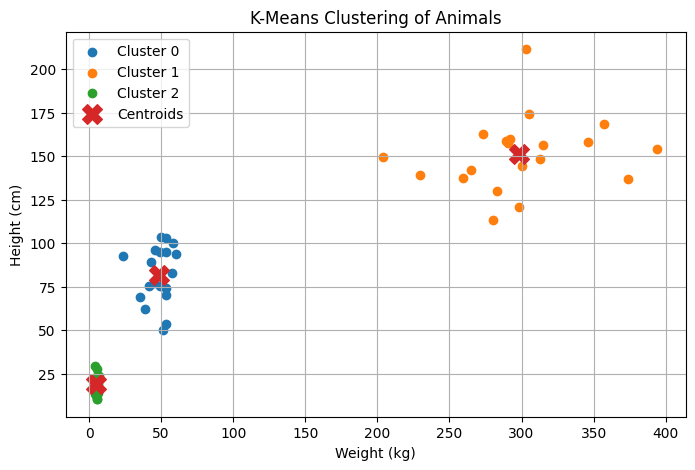

In [5]:


plt.figure(figsize=(8, 5))

for cluster in sorted(X_animals['Cluster'].unique()):
    group = X_animals[X_animals['Cluster'] == cluster]

    plt.scatter(
        group['Weight_kg'],
        group['Height_cm'],
        label=f'Cluster {cluster}'
    )

# Plot centroids in original units
centroids_original = scaler.inverse_transform(
    kmeans.cluster_centers_
)

plt.scatter(
    centroids_original[:, 0],
    centroids_original[:, 1],
    marker='X',
    s=200,
    label='Centroids'
)

plt.xlabel('Weight (kg)')
plt.ylabel('Height (cm)')
plt.title('K-Means Clustering of Animals')
plt.legend()
plt.grid(True)
plt.show()

ACTIVITY 2

In [6]:

import pandas as pd
import numpy as np

from sklearn.cluster import AgglomerativeClustering
from scipy.cluster.hierarchy import dendrogram, linkage

import matplotlib.pyplot as plt

In [7]:


np.random.seed(42)

# Create synthetic data with some groupings
X_students = pd.DataFrame({
    'Study_Hours_Week': np.random.randint(5, 40, 50),
    'Sleep_Hours_Night': np.random.uniform(4, 9, 50).round(1)
})

# Add some patterns
X_students.loc[
    X_students['Study_Hours_Week'] > 30,
    'Sleep_Hours_Night'
] = np.random.uniform(
    4, 6,
    sum(X_students['Study_Hours_Week'] > 30)
).round(1)

X_students.loc[
    X_students['Study_Hours_Week'] < 10,
    'Sleep_Hours_Night'
] = np.random.uniform(
    7, 9,
    sum(X_students['Study_Hours_Week'] < 10)
).round(1)

print("Student Habit Data (first 5 rows):\n",
      X_students.head())

Student Habit Data (first 5 rows):
    Study_Hours_Week  Sleep_Hours_Night
0                33                5.0
1                19                6.0
2                12                8.6
3                25                7.6
4                23                5.6


In [8]:


hierarchical = AgglomerativeClustering(
    n_clusters=2,
    linkage='ward'
)

student_labels = hierarchical.fit_predict(X_students)

X_students['Cluster'] = student_labels

print("Student data with clusters:")
print(X_students.head(10))

print("\nNumber of students in each cluster:")
print(X_students['Cluster'].value_counts().sort_index())

Student data with clusters:
   Study_Hours_Week  Sleep_Hours_Night  Cluster
0                33                5.0        0
1                19                6.0        0
2                12                8.6        1
3                25                7.6        0
4                23                5.6        0
5                27                6.9        0
6                15                6.6        1
7                15                8.8        1
8                28                8.2        0
9                28                7.7        0

Number of students in each cluster:
Cluster
0    31
1    19
Name: count, dtype: int64


In [9]:


cluster_summary = X_students.groupby('Cluster')[
    ['Study_Hours_Week', 'Sleep_Hours_Night']
].mean()

print("Average habits for each cluster:")
print(cluster_summary)

Average habits for each cluster:
         Study_Hours_Week  Sleep_Hours_Night
Cluster                                     
0               26.870968           6.232258
1               10.000000           7.815789
